The full transmon qubit Hamiltonian in the phase basis is:
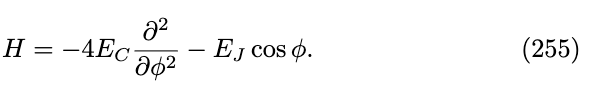

The pictures are from another course advanced quantum science im taking at UTS I have attached the notes in the folder.

This is a second order ODE.  H $\psi$=E $\psi$

In [1]:
#step 1: Since this is the phase basis the boundary conditions restricts that psi of phi must be equal to psi of phi + 2pi. This means that the wavefunction must be periodic in phi with a period of 2pi.
# create the lattice in phi space
import numpy as np
import matplotlib.pyplot as plt
phi = np.linspace(- np.pi, np.pi, 1000, endpoint=False)  # Create a lattice in phi space from -pi to pi
# I only include one of the endpoints because the wavefunction is periodic.

Matplotlib is building the font cache; this may take a moment.


In [2]:
# step two write the second order derivative with finite difference method.
# I use the definition of D2 with boundary conditions from week 11.
def D2(N,h):
    D2 = np.zeros((N,N))
    for i in range(N):
        for j in range(N):
            if 0<i<(N-1): # excluding the first and last row
                if i==j:
                    D2[i,j]=-2 #diagonal elements
                elif (j==i-1) or (j==i+1): # the two neigbours of the diagonal
                    D2[i,j]=1
            else:
                if i==0: #first row because of the periodic condition even the end points have neighbours
                    if i==j:
                        D2[i,j]=-2
                    elif j==i+1 or j==N-1:
                        D2[i,j]=1
                if i==N-1: #last row
                    if i==j:
                        D2[i,j]=-2
                    elif j==0 or j==i-1:
                        D2[i,j]=1
    return(D2/h**2)




In [3]:
D2(4000,1) # it works but I am saving all the zeroes which is waste of computation

array([[-2.,  1.,  0., ...,  0.,  0.,  1.],
       [ 1., -2.,  1., ...,  0.,  0.,  0.],
       [ 0.,  1., -2., ...,  0.,  0.,  0.],
       ...,
       [ 0.,  0.,  0., ..., -2.,  1.,  0.],
       [ 0.,  0.,  0., ...,  1., -2.,  1.],
       [ 1.,  0.,  0., ...,  0.,  1., -2.]])

In [4]:
# I try implementing sparse also easier
from scipy import sparse as sp
from scipy.sparse import linalg as sla
def SD2(N,h):
    M=N-1 # since the upper and lower diagonal has 1 less element than the diagonal
    AD=np.diag(-2*np.ones(N),0)# 0 main diagonal
    AO=np.diag(np.ones(M),1)# +1 over main diagonal
    AL=np.diag(np.ones(M),-1)# -1 over main diagonal
    AP = np.diag([1],M) + np.diag([1],-M) # the boundary condition
    D2=sp.csr_matrix((AD+AO+AL+AP)/h**2)
    return(D2)



In [5]:
print(SD2(4,1).todense()) # works and it is sparse so it saves memory and computation time.

[[-2.  1.  0.  1.]
 [ 1. -2.  1.  0.]
 [ 0.  1. -2.  1.]
 [ 1.  0.  1. -2.]]


In [6]:
SD2(4000,1).todense() # 16x faster than the dense matrix.

matrix([[-2.,  1.,  0., ...,  0.,  0.,  1.],
        [ 1., -2.,  1., ...,  0.,  0.,  0.],
        [ 0.,  1., -2., ...,  0.,  0.,  0.],
        ...,
        [ 0.,  0.,  0., ..., -2.,  1.,  0.],
        [ 0.,  0.,  0., ...,  1., -2.,  1.],
        [ 1.,  0.,  0., ...,  0.,  1., -2.]])

In [7]:
# The next turn in the hamilton -Ej cos(phi) is a diagonal matrix with the values of -Ej cos(phi) on the diagonal.
def SV(phi):
    AD=np.diag(np.cos(phi),0)# 0 main diagonal
    SV=sp.csr_matrix(AD)
    return(SV)

I can now create the full hamiltonian

In [8]:
N=1000
h= 2*np.pi /N
E_j, E_c =1, 1/100 # since Ej>>Ec
phi = np.linspace(- np.pi, np.pi, N, endpoint=False) 
H = -4*E_c *SD2(N,h)- E_j*SV(phi)

In [9]:
H.todense() #the full hamilton, because I use sparse im able to do it for very big N

matrix([[ 2027.42367285, -1013.21183642,     0.        , ...,
             0.        ,     0.        , -1013.21183642],
        [-1013.21183642,  2027.42365311, -1013.21183642, ...,
             0.        ,     0.        ,     0.        ],
        [    0.        , -1013.21183642,  2027.42359389, ...,
             0.        ,     0.        ,     0.        ],
        ...,
        [    0.        ,     0.        ,     0.        , ...,
          2027.4234952 , -1013.21183642,     0.        ],
        [    0.        ,     0.        ,     0.        , ...,
         -1013.21183642,  2027.42359389, -1013.21183642],
        [-1013.21183642,     0.        ,     0.        , ...,
             0.        , -1013.21183642,  2027.42365311]])

In [10]:
from scipy.sparse import linalg as sla
E,U = sla.eigsh(H, k=3, which='SA') # I use the sparse matrix to find the eigenvalues and eigenvectors. k is the number of eigenvalues and eigenvectors to find. which='SA' means that I want the smallest algebraic eigenvalues.

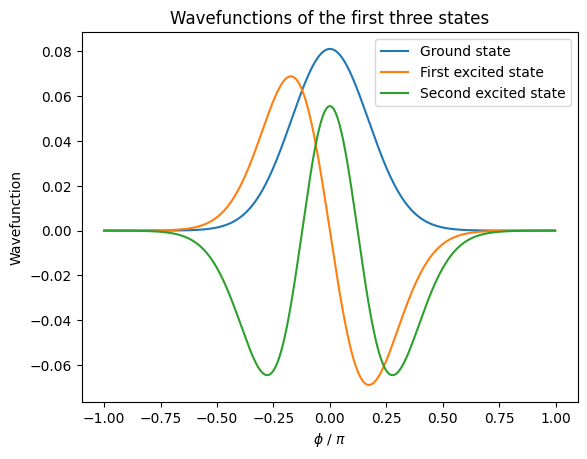

Eigenvalues: E0= -0.8611265461504206 E1= -0.5886795335398319 E2= -0.3271910343888513
Energy gap between ground state and first excited state: DE_01= 0.2724470126105887
Energy gap between first excited state and second excited state: DE_12= 0.26148849915098066
difference between the energy gaps: DE_12-DE_01= -0.010958513459608021


In [11]:
plt.plot(phi/(np.pi),U[:,0], label='Ground state') # the ground state wavefunction
plt.plot(phi/(np.pi),U[:,1], label='First excited state') # the first excited state wavefunction
plt.plot(phi/(np.pi),U[:,2], label='Second excited state') # the second excited state wavefunction
plt.legend()
plt.xlabel('$\phi$ / $\pi$')
plt.ylabel('Wavefunction')
plt.title('Wavefunctions of the first three states')
plt.show()
print('Eigenvalues:', 'E0=', E[0], 'E1=', E[1], 'E2=', E[2]) # the eigenvalues of the hamiltonian
print('Energy gap between ground state and first excited state:', 'DE_01=', E[1]-E[0]) 
print('Energy gap between first excited state and second excited state:', 'DE_12=', E[2]-E[1]) 
print('difference between the energy gaps:', 'DE_12-DE_01=', (E[2]-E[1])-(E[1]-E[0]))

The first three wawefunctions. They shift between being even and odd functions as they should and have different energy gaps between the states meaning you can induce shifts between specific states (eg. ground and first excited) the ground state has 0 nodes the first 1 and the second has two like a harmonic oscilator.

The hamilton system is much simpler to implement in the numbers basis where it is given by:
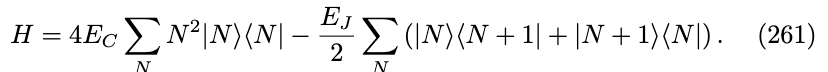

The eigenvalues should be the same, the states should not

In [12]:
def H_number(N, Ec, Ej):
    M=len(N)-1 # since the upper and lower diagonal has 1 less element than the diagonal
    K= 4*Ec*np.diag(N**2,0)
    V= -Ej/2 * (np.diag(np.ones(M),1)+np.diag(np.ones(M),-1))
    H=sp.csr_matrix(K+V)
    return(H) 

In [13]:
N=np.arange(-10,11,1) # the number of Cooper pairs from -10 to 10
E_j, E_c =1, 1/100 # same as before
H_num = H_number(N, E_c, E_j) # the hamiltonian in n basis
E_num,U_num = sla.eigsh(H_num, k=3, which='SA') # the eigenvalues and eigenvectors in n basis
print('Eigenvalues in n basis:', 'E0=', E_num[0], 'E1=', E_num[1], 'E2=', E_num[2]) # the eigenvalues of the hamiltonian in n basis
print('Eigenvalues in phi basis:', 'E0=', E[0], 'E1=', E[1], 'E2=', E[2]) # the eigenvalues of the hamiltonian

Eigenvalues in n basis: E0= -0.8611253852863612 E1= -0.588674029910954 E2= -0.32717761702713455
Eigenvalues in phi basis: E0= -0.8611265461504206 E1= -0.5886795335398319 E2= -0.3271910343888513


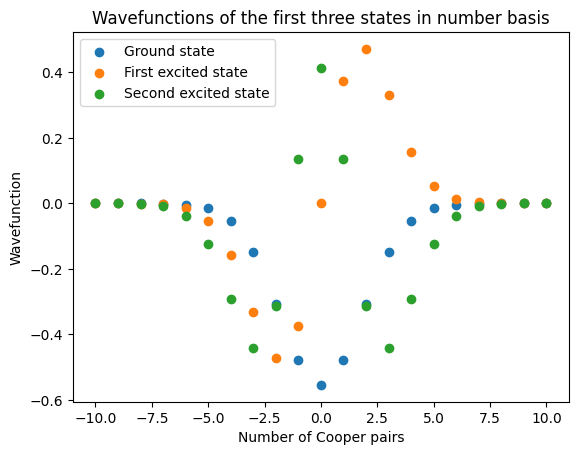

In [14]:
plt.scatter(N,U_num[:,0], label='Ground state') # the ground state wavefunction
plt.scatter(N,U_num[:,1], label='First excited state') # the first excited state wavefunction
plt.scatter(N,U_num[:,2], label='Second excited state') # the second excited state wavefunction
plt.legend()
plt.xlabel('Number of Cooper pairs')
plt.ylabel('Wavefunction')
plt.title('Wavefunctions of the first three states in number basis')    
plt.show()